# BigMart Sales: EDA and Data Cleaning

**Goal:** clean the BigMart data and explore it before building a model that predicts `Item_Outlet_Sales`
(the sales of a product in a store). The target is a **number**, so this is a **regression** problem.

## Step 1: Load the data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("train.csv")
df.shape

(8523, 12)

In [3]:
df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [4]:
df.dtypes

Item_Identifier                  str
Item_Weight                  float64
Item_Fat_Content                 str
Item_Visibility              float64
Item_Type                        str
Item_MRP                     float64
Outlet_Identifier                str
Outlet_Establishment_Year      int64
Outlet_Size                      str
Outlet_Location_Type             str
Outlet_Type                      str
Item_Outlet_Sales            float64
dtype: object

---
**Step 1 takeaway**
- **What we did:** Loaded `train.csv` (8,523 rows x 12 columns).
- **Why:** To see what each row means and what we are predicting.
- **What we learnt:** Each row is one product in one store. The target `Item_Outlet_Sales` is a number, so this is a **regression** problem.
---

## Step 2: Sampling (only if the data is too big)

In [5]:
print("Rows:", len(df))
# 8,523 rows is small enough for a laptop, so no sampling. We use all the data.

Rows: 8523


---
**Step 2 takeaway**
- **What we did:** Checked the number of rows.
- **Why:** Sampling is only needed when the data is too big for a laptop.
- **What we learnt:** 8,523 rows is small, so we use all the data.
---

## Step 3: Column lists

- `feature_cols`: numeric input columns
- `numeric_cols`: numeric inputs + the target (all get missing-value and outlier checks)
- `cat_cols`: text columns, plus `Outlet_Establishment_Year`. The year has only 9 different values, so we treat it as a **group**, not a measurement.
- Left out: `Item_Identifier` (1,559 product codes) and `Outlet_Identifier` (store codes). They are IDs, not measurements.

In [6]:
feature_cols = ["Item_Weight", "Item_Visibility", "Item_MRP"]
target = "Item_Outlet_Sales"
numeric_cols = ["Item_Weight", "Item_Visibility", "Item_MRP", "Item_Outlet_Sales"]
cat_cols = ["Item_Fat_Content", "Item_Type", "Outlet_Size", "Outlet_Location_Type",
            "Outlet_Type", "Outlet_Establishment_Year"]

In [7]:
# How many different products and stores are there?
print("Different products:", df["Item_Identifier"].nunique())
print("Different stores:", df["Outlet_Identifier"].nunique())

Different products: 1559
Different stores: 10


---
**Step 3 takeaway**
- **What we did:** Split the columns into numeric inputs, the target and group columns, and left out the IDs.
- **Why:** Numbers and groups need different checks and different plots.
- **What we learnt:** There are only 3 numeric inputs. Most of the information is in group columns (item type and store details). The year acts as a store label, not a measurement.
---

## Step 4: Inconsistencies and invalid values

In [8]:
# See every different value in each group column
for col in cat_cols:
    print(col, df[col].unique())

Item_Fat_Content <StringArray>
['Low Fat', 'Regular', 'low fat', 'LF', 'reg']
Length: 5, dtype: str
Item_Type <StringArray>
[                'Dairy',           'Soft Drinks',                  'Meat',
 'Fruits and Vegetables',             'Household',          'Baking Goods',
           'Snack Foods',          'Frozen Foods',             'Breakfast',
    'Health and Hygiene',           'Hard Drinks',                'Canned',
                'Breads',         'Starchy Foods',                'Others',
               'Seafood']
Length: 16, dtype: str
Outlet_Size <StringArray>
['Medium', nan, 'High', 'Small']
Length: 4, dtype: str
Outlet_Location_Type <StringArray>
['Tier 1', 'Tier 3', 'Tier 2']
Length: 3, dtype: str
Outlet_Type <StringArray>
['Supermarket Type1', 'Supermarket Type2', 'Grocery Store',
 'Supermarket Type3']
Length: 4, dtype: str
Outlet_Establishment_Year [1999 2009 1998 1987 1985 2002 2007 1997 2004]


Only `Item_Fat_Content` is messy: "Low Fat", "low fat" and "LF" mean the same thing, and so do "Regular" and "reg".
All other columns are already clean, nothing to fix.

In [9]:
# strip() removes extra spaces, lower() makes everything small letters
df["Item_Fat_Content"] = df["Item_Fat_Content"].str.strip().str.lower()

# Fix the short forms (left = wrong, right = correct)
df["Item_Fat_Content"] = df["Item_Fat_Content"].replace({"lf": "low fat", "reg": "regular"})

df["Item_Fat_Content"].unique()

<StringArray>
['low fat', 'regular']
Length: 2, dtype: str

In [10]:
# Look at min and max to spot impossible values
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


`Item_Visibility` (the % of the store's display area given to the product) has a **minimum of 0**.
A product that is being sold must be visible on the shelf, so 0 is impossible. We count them and turn them into NaN, so they get filled in Step 6.

In [11]:
print("Item_Visibility = 0:", (df["Item_Visibility"] == 0).sum())
df.loc[df["Item_Visibility"] == 0, "Item_Visibility"] = np.nan

Item_Visibility = 0: 526


---
**Step 4 takeaway**
- **What we did:** Printed every group value and compared the `describe()` min/max with what's possible.
- **Why:** Messy spellings split one group into many, and impossible values distort averages.
- **What we learnt:** `Item_Fat_Content` had 5 spellings of 2 values, now fixed. 526 rows had visibility 0, which is impossible, so they were turned into NaN.
---

## Step 5: Duplicates

In [12]:
print("Duplicate rows:", df.duplicated().sum())
# 0 -> already clean, nothing to remove

Duplicate rows: 0


---
**Step 5 takeaway**
- **What we did:** Checked for duplicate rows.
- **Why:** Duplicates would count the same sale twice.
- **What we learnt:** There are no duplicates.
---

## Step 6: Missing values

In [13]:
# Number of missing values, then % missing, in each column
print(df.isnull().sum())
missing_pct = df.isnull().sum() / len(df) * 100
missing_pct

Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility               526
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64


Item_Identifier               0.000000
Item_Weight                  17.165317
Item_Fat_Content              0.000000
Item_Visibility               6.171536
Item_Type                     0.000000
Item_MRP                      0.000000
Outlet_Identifier             0.000000
Outlet_Establishment_Year     0.000000
Outlet_Size                  28.276428
Outlet_Location_Type          0.000000
Outlet_Type                   0.000000
Item_Outlet_Sales             0.000000
dtype: float64

Nothing is near the 75% "drop the column" limit, so we fill everything.

**Numbers:** `Item_Weight` (17%) and `Item_Visibility` (the zeros from Step 4) are filled with the **median**, which isn't pulled by outliers.

In [14]:
# Which stores have Item_Weight missing?
df.loc[df["Item_Weight"].isnull(), "Outlet_Identifier"].value_counts()

Outlet_Identifier
OUT027    935
OUT019    528
Name: count, dtype: int64

In [15]:
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

**Outlet_Size** (28% missing): the normal rule is the mode. First, we check which stores are missing it.

In [16]:
# Which store types have Outlet_Size missing?
print(df.loc[df["Outlet_Size"].isnull(), "Outlet_Type"].value_counts())
print()
# What size are the stores of each type, where we know it?
pd.crosstab(df["Outlet_Type"], df["Outlet_Size"])

Outlet_Type
Supermarket Type1    1855
Grocery Store         555
Name: count, dtype: int64



Outlet_Size,High,Medium,Small
Outlet_Type,,,
Grocery Store,0,0,528
Supermarket Type1,932,930,1860
Supermarket Type2,0,928,0
Supermarket Type3,0,935,0


The missing sizes are all **Grocery Stores** and **Supermarket Type1**.
- Every grocery store with a known size is **Small**.
- Supermarket Type1 is most often **Small** too.

The overall mode is "Medium", which would call a grocery store a medium-sized store. So we fill with **"Small"**,
the most common size **for the store types that are missing**.

In [17]:
df["Outlet_Size"] = df["Outlet_Size"].fillna("Small")

df.isnull().sum()

Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
dtype: int64

---
**Step 6 takeaway**
- **What we did:** Printed the % missing, filled the numbers with the median, and checked `Outlet_Size` against store type.
- **Why:** Models can't handle empty values, and a careless fill can put wrong values into a quarter of the data.
- **What we learnt:** Missing `Outlet_Size` belongs to whole stores (grocery stores and Type1 supermarkets), which are mostly Small. The overall mode ("Medium") would have been wrong.
---

## Step 7: Outliers

Two methods from the notes:
- **3 sigma:** outlier if outside mean ± 3 x std. Works well only when the data is roughly normal (bell-shaped).
- **IQR:** outlier if outside Q1 - 1.5xIQR or Q3 + 1.5xIQR. Uses quartiles, so it also works on skewed data.

Before removing anything, we also check **which store type** the outliers come from.

In [18]:
for col in numeric_cols:
    # IQR method
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    col_outliers = (df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)

    # 3 sigma method
    mean = df[col].mean()
    std = df[col].std()
    sigma_count = ((df[col] < mean - 3 * std) | (df[col] > mean + 3 * std)).sum()

    print(f"{col} | IQR outliers: {col_outliers.sum()} | 3 sigma outliers: {sigma_count}")
    if col_outliers.sum() > 0:
        print(df.loc[col_outliers, "Outlet_Type"].value_counts(), "\n")

Item_Weight | IQR outliers: 0 | 3 sigma outliers: 0


Item_Visibility | IQR outliers: 173 | 3 sigma outliers: 100
Outlet_Type
Grocery Store        167
Supermarket Type1      5
Supermarket Type2      1
Name: count, dtype: int64 

Item_MRP | IQR outliers: 0 | 3 sigma outliers: 0
Item_Outlet_Sales | IQR outliers: 186 | 3 sigma outliers: 90
Outlet_Type
Supermarket Type3    103
Supermarket Type1     80
Supermarket Type2      3
Name: count, dtype: int64 



In [19]:
# For comparison: how many rows each store type has in the whole data
df["Outlet_Type"].value_counts()

Outlet_Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64

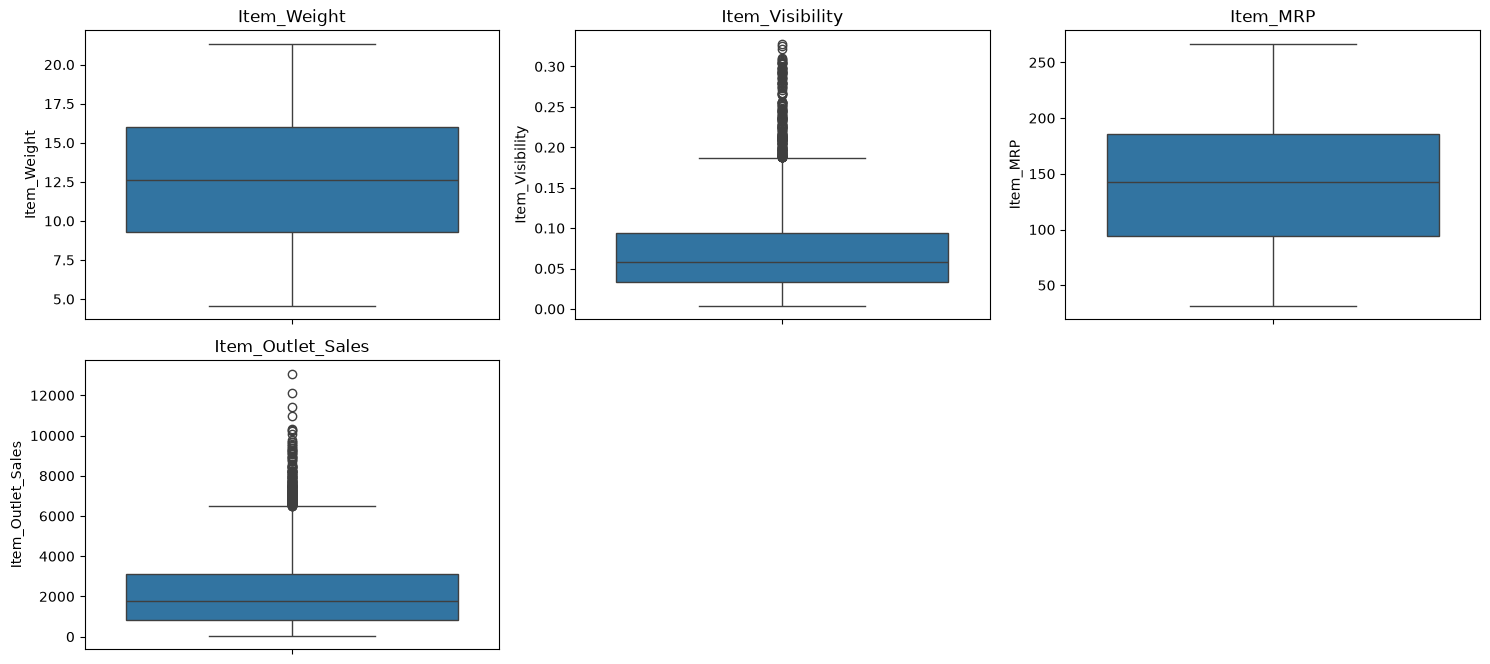

In [20]:
# Box plots of the numeric columns
plt.figure(figsize=(15, 10))   # 3x3 grid = up to 9 plots, like the lab
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

**Decision: we do NOT remove outliers.**
- `Item_Visibility`: almost all outliers are in **Grocery Stores**. Small shops sell fewer products, so each product gets a bigger share of the shelf. These are real values, not mistakes.
- `Item_Outlet_Sales`: more than half of the outliers come from **Supermarket Type3**, even though it has only about 11% of the rows.
  Type3 stores really do sell the most. Removing these rows would delete that pattern, and the model would under-predict sales for Type3 stores.
- `Item_Weight` and `Item_MRP` have no outliers.

---
**Step 7 takeaway**
- **What we did:** Counted outliers with IQR and 3 sigma, then checked which store types they come from.
- **Why:** To find out whether the outliers are mistakes or real behaviour before deleting anything.
- **What we learnt:** Visibility outliers are grocery stores (fewer products, so more shelf space each), and sales outliers are mostly Type3 supermarkets (the best sellers). They are real, so they were **kept**.
---

## Step 8: Univariate analysis (one column at a time)

In [21]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,8523.00000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.81342,0.069699,140.992782,1997.831867,2181.288914
std,4.22724,0.048826,62.275067,8.371760,1706.499616
min,4.55500,0.003575,31.290000,1985.000000,33.290000
25%,9.31000,0.033085,93.826500,1987.000000,834.247400
50%,12.60000,0.057792,143.012800,1999.000000,1794.331000
75%,16.00000,0.094585,185.643700,2004.000000,3101.296400
max,21.35000,0.328391,266.888400,2009.000000,13086.964800


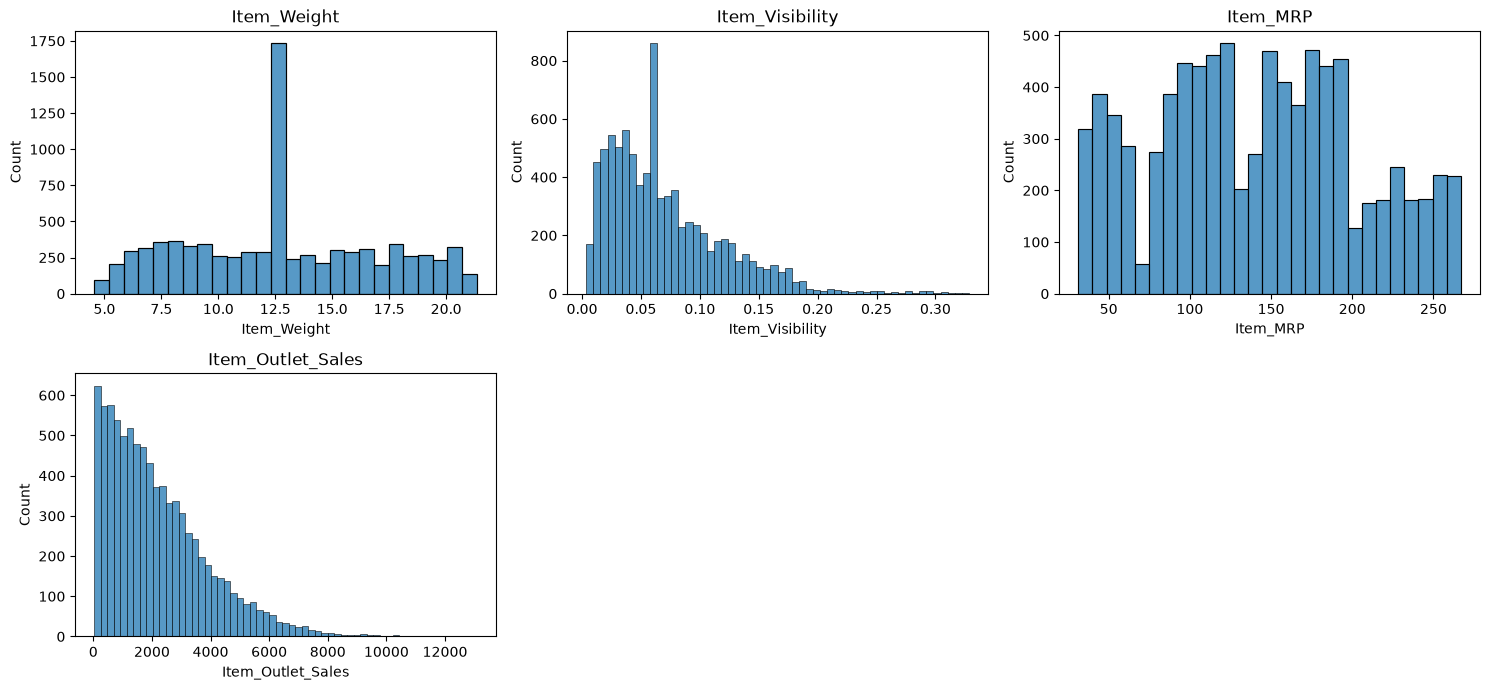

In [22]:
# Histograms: shape of each numeric column (normal, skewed, etc.)
plt.figure(figsize=(15, 10))   # 3x3 grid = up to 9 plots, like the lab
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

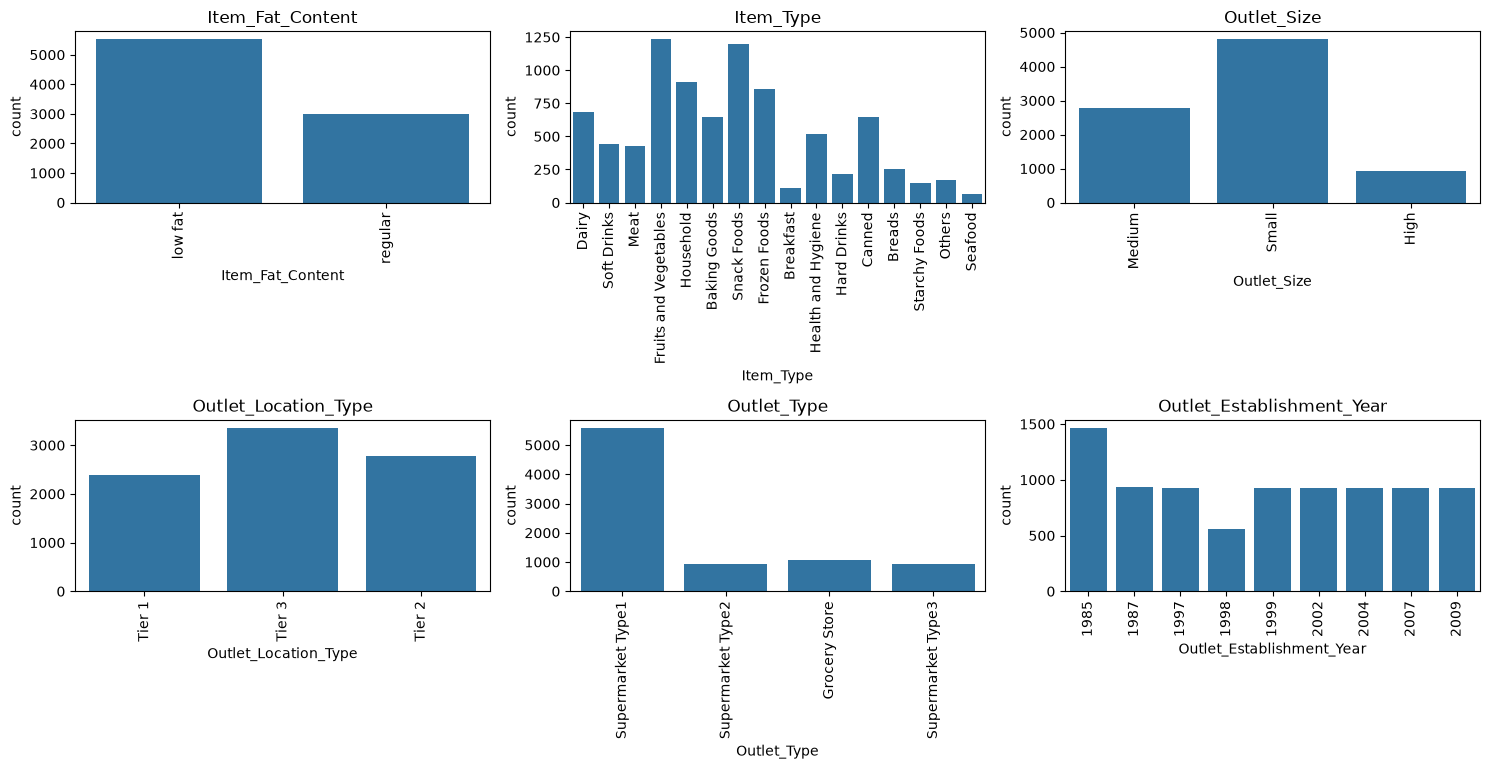

In [23]:
# Count plots: how many rows in each group
plt.figure(figsize=(15, 10))   # 3x3 grid = up to 9 plots, like the lab
for i, col in enumerate(cat_cols, 1):
    plt.subplot(3, 3, i)
    sns.countplot(x=df[col])
    plt.xticks(rotation=90)    # turn the labels so long names don't overlap
    plt.title(col)
plt.tight_layout()
plt.show()

In [24]:
# Exact counts for fat content
df["Item_Fat_Content"].value_counts()

Item_Fat_Content
low fat    5517
regular    3006
Name: count, dtype: int64

What the plots show:
- The target `Item_Outlet_Sales` is **right-skewed**: many small sales, a few very large ones. (Note for modelling: linear regression may work better on a transformed target. See "variable transformation" in the notes.)
- `Item_Visibility` is right-skewed too.
- `Item_MRP` (price) falls into **4 price bands**, with gaps between them.
- The tall bar at 12.6 in `Item_Weight` and the one at about 0.058 in `Item_Visibility` are the missing values we filled with the median in Step 6.
- Most products are low fat (5,517 vs 3,006). Fruits & Vegetables and Snack Foods are the most common types, and most rows come from Supermarket Type1 stores.

---
**Step 8 takeaway**
- **What we did:** Looked at histograms and count plots, one column at a time.
- **Why:** To understand each column's shape and spread.
- **What we learnt:** Sales are right-skewed. Price falls into 4 bands. The spikes in weight and visibility come from our median fill. Most rows are Type1 supermarkets.
---

## Step 9: Bivariate analysis (two columns together)

**Correlation heatmap:** correlation of every pair of numeric columns (-1 to +1).
- Feature vs target close to +1 or -1 means it is useful for predicting (linear regression assumption: IV-DV correlation).
- Two features highly correlated with each other means **multicollinearity** (linear regression assumption: there should be none).
- `annot=True` writes the number inside each box.

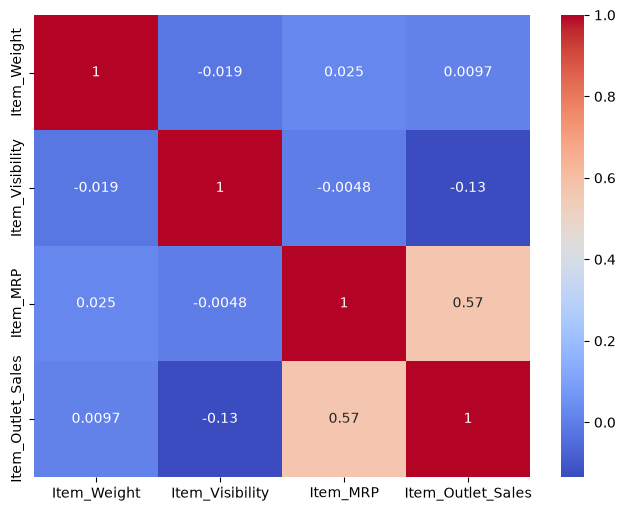

In [25]:
corr = df[numeric_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

### VIF (Variance Inflation Factor)
The heatmap only compares **two columns at a time**. VIF checks whether a column can be predicted from **all the other input columns together**.
- For each column, we fit a linear regression that predicts it from all the other input columns, and get the **R²** (how well they predict it).
- **VIF = 1 / (1 - R²)**. If the other columns predict it almost perfectly (R² close to 1), VIF becomes very large.
- From the notes: **VIF = 1 means no multicollinearity, 1 to 5 is acceptable, 5 or more is a concern.**
- Why it matters: with multicollinearity it's hard to interpret each column's individual coefficient, because the model can't tell which of the similar columns is doing the work.
- The target is not included. VIF is only about the input columns.

In [26]:
from sklearn.linear_model import LinearRegression

vif_cols = feature_cols   # input columns only (no target)

for col in vif_cols:
    X = df[vif_cols].drop(columns=[col])   # all the other columns
    y = df[col]                            # the column we try to predict from them
    model = LinearRegression()
    model.fit(X, y)
    r2 = model.score(X, y)                 # score() gives R² for a linear regression
    vif = 1 / (1 - r2)
    print(f"{col} | R²: {r2:.3f} | VIF: {vif:.2f}")

Item_Weight | R²: 0.001 | VIF: 1.00
Item_Visibility | R²: 0.000 | VIF: 1.00
Item_MRP | R²: 0.001 | VIF: 1.00


**Result:** all VIFs are about **1.0**, so there is **no multicollinearity**. This matches the heatmap, where the inputs have correlations near 0 with each other.

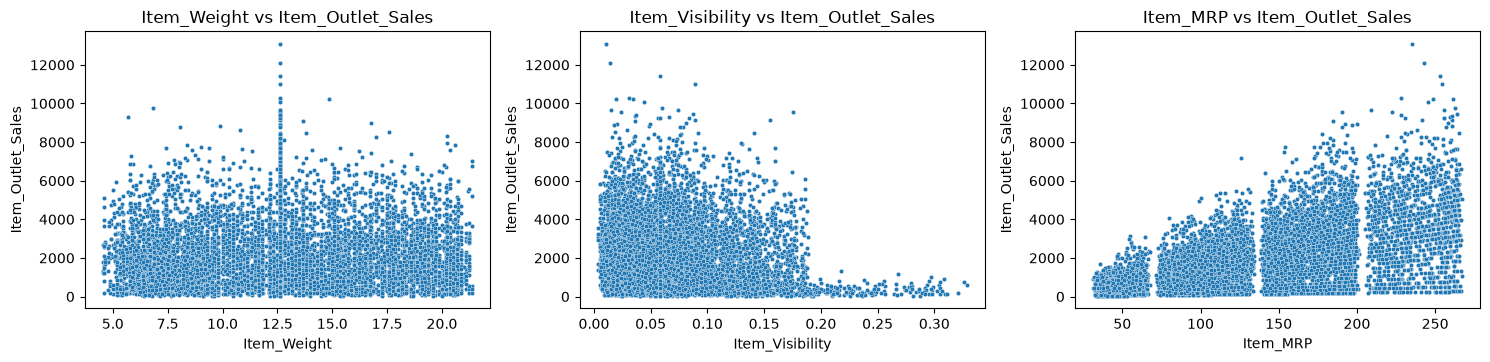

In [27]:
# Scatter plot of each numeric input vs the target
# (linear regression assumption: the relationship should look like a straight line)
plt.figure(figsize=(15, 10))   # 3x3 grid = up to 9 plots, like the lab
for i, col in enumerate(feature_cols, 1):
    plt.subplot(3, 3, i)
    sns.scatterplot(x=df[col], y=df[target], s=10)   # s=10 makes the dots smaller
    plt.title(col + " vs " + target)
plt.tight_layout()
plt.show()

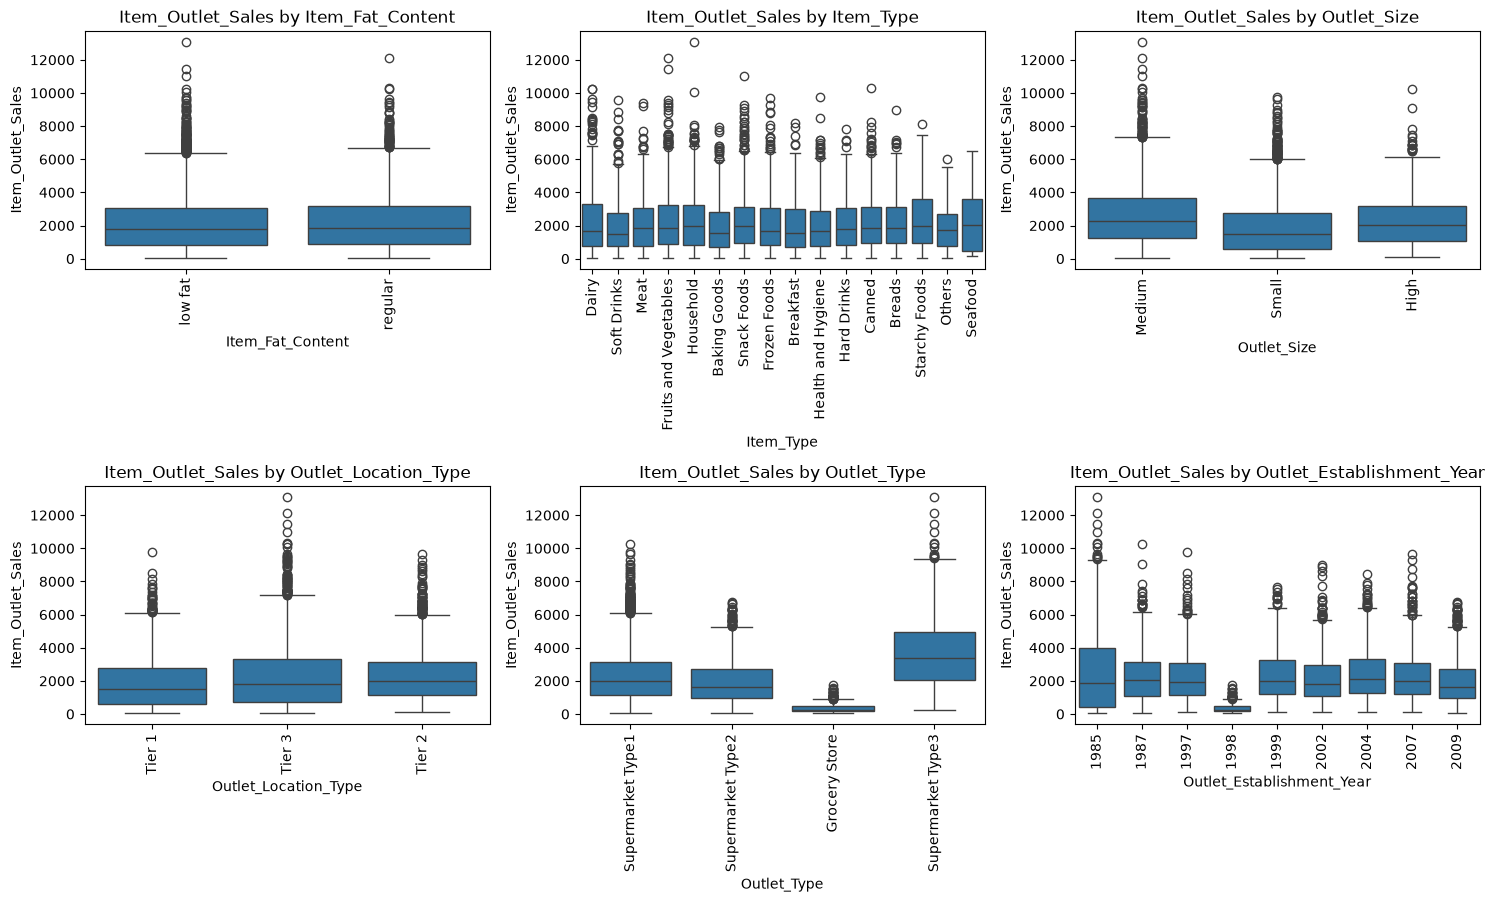

In [28]:
# Box plot of the target (sales) for each group
plt.figure(figsize=(15, 12))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=df[col], y=df[target])
    plt.xticks(rotation=90)
    plt.title(target + " by " + col)
plt.tight_layout()
plt.show()

In [29]:
# Median sales in each group (the middle line of each box above)
# Same idea as SELECT col, MEDIAN(sales) ... GROUP BY col in SQL
for col in cat_cols:
    medians = df.groupby(col)[target].median()
    print(medians.round(0), "\n")

Item_Fat_Content
low fat    1765.0
regular    1845.0
Name: Item_Outlet_Sales, dtype: float64 

Item_Type
Baking Goods             1578.0
Breads                   1860.0
Breakfast                1555.0
Canned                   1860.0
Dairy                    1651.0
Frozen Foods             1687.0
Fruits and Vegetables    1831.0
Hard Drinks              1817.0
Health and Hygiene       1669.0
Household                1981.0
Meat                     1830.0
Others                   1714.0
Seafood                  2055.0
Snack Foods              1944.0
Soft Drinks              1518.0
Starchy Foods            1968.0
Name: Item_Outlet_Sales, dtype: float64 

Outlet_Size
High      2051.0
Medium    2251.0
Small     1484.0
Name: Item_Outlet_Sales, dtype: float64 

Outlet_Location_Type
Tier 1    1487.0
Tier 2    2004.0
Tier 3    1812.0
Name: Item_Outlet_Sales, dtype: float64 

Outlet_Type
Grocery Store         257.0
Supermarket Type1    1991.0
Supermarket Type2    1655.0
Supermarket Type3    3365.

In [30]:
# One row per store: its opening year, type, size and location
store_cols = ["Outlet_Establishment_Year", "Outlet_Type", "Outlet_Size", "Outlet_Location_Type"]
stores = df.groupby("Outlet_Identifier")[store_cols].first()
stores

,Outlet_Establishment_Year,Outlet_Type,Outlet_Size,Outlet_Location_Type
Outlet_Identifier,,,,
OUT010,1998,Grocery Store,Small,Tier 3
OUT013,1987,Supermarket Type1,High,Tier 3
OUT017,2007,Supermarket Type1,Small,Tier 2
OUT018,2009,Supermarket Type2,Medium,Tier 3
OUT019,1985,Grocery Store,Small,Tier 1
OUT027,1985,Supermarket Type3,Medium,Tier 3
OUT035,2004,Supermarket Type1,Small,Tier 2
OUT045,2002,Supermarket Type1,Small,Tier 2
OUT046,1997,Supermarket Type1,Small,Tier 1


What the plots show:
- **Heatmap:** `Item_MRP` has by far the strongest link with sales (**0.57**): more expensive products bring in more sales.
  `Item_Visibility` is weak and negative (-0.13), and `Item_Weight` has no link (0.01).
- **No multicollinearity:** the inputs are about 0 correlated with each other.
- **Scatter plots:** `Item_MRP` vs sales goes up in a roughly straight line (the linearity assumption is OK), but the spread gets wider as the price rises.
  That fan shape matters for the **homoscedasticity** assumption, which we check after building the model.
  `Item_Weight` shows no pattern. The vertical line at 12.6 is the filled values.
  Products with very high visibility (above about 0.19) have low sales: these are the grocery-store rows from Step 7.
- **Box plots:** `Outlet_Type` makes the biggest difference. Grocery stores sell far less (median about 257) and Supermarket Type3 the most (median about 3,365).
  1998 looks very low because the only store opened that year is a grocery store, and 1985 looks wide because it has both a grocery store and the Type3 store.
  `Item_Fat_Content` and `Item_Type` make little difference.

---
**Step 9 takeaway**
- **What we did:** Built a correlation heatmap, scatter plots against sales, and box plots of sales by group.
- **Why:** To find what drives sales, and to check the linear regression assumptions (linearity, multicollinearity with heatmap + VIF).
- **What we learnt:** **Price** (0.57) and **store type** drive sales: Type3's median is about 13x a grocery store's. Product type, fat content and weight barely matter. There is no multicollinearity (all VIFs about 1.0), but sales spread out more at high prices (fan shape).
---

## Step 10: Save the clean data

In [31]:
df.to_csv("bigmart_clean.csv", index=False)   # index=False: don't save the row numbers as a column
df.shape

(8523, 12)

---
**Step 10 takeaway**
- **What we did:** Saved the cleaned data.
- **Why:** To keep a readable copy (group names, not 0/1 columns) for reports and charts, before encoding.
- **What we learnt:** The final clean data is 8,523 rows x 12 columns, with no missing values.
---

## Step 11: Encoding (one-hot, like the lab)

Models only understand numbers, so the text columns in `cat_cols` have to become numbers.
- `pd.get_dummies` makes a new **0/1 column for each category**. This is one-hot encoding.
- `drop_first=True` removes the first category of each column (alphabetically first). No information is lost: if all the other 0/1 columns are 0, the row must be that category.
  Keeping it would make the 0/1 columns always add up to 1, which is perfect **multicollinearity** (the "dummy variable trap").
- `dtype=int` gives 0/1 instead of True/False.

`Outlet_Establishment_Year` is in `cat_cols` (we treated it as a group in the EDA), so it gets one-hot encoded too.

First we drop the ID columns. They are labels, not measurements.

In [32]:
# IDs are labels, not measurements -> drop before modelling
df = df.drop(columns=['Item_Identifier', 'Outlet_Identifier'])

print("Shape before encoding:", df.shape)
df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
print("Shape after encoding:", df.shape)
df.head()

Shape before encoding: (8523, 10)
Shape after encoding: (8523, 35)


,Item_Weight,Item_Visibility,Item_MRP,Item_Outlet_Sales,Item_Fat_Content_regular,Item_Type_Breads,Item_Type_Breakfast,Item_Type_Canned,Item_Type_Dairy,Item_Type_Frozen Foods,...,Outlet_Type_Supermarket Type2,Outlet_Type_Supermarket Type3,Outlet_Establishment_Year_1987,Outlet_Establishment_Year_1997,Outlet_Establishment_Year_1998,Outlet_Establishment_Year_1999,Outlet_Establishment_Year_2002,Outlet_Establishment_Year_2004,Outlet_Establishment_Year_2007,Outlet_Establishment_Year_2009
0,9.30,0.016047,249.8092,3735.1380,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
1,5.92,0.019278,48.2692,443.4228,1,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
2,17.50,0.016760,141.6180,2097.2700,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,19.20,0.057792,182.0950,732.3800,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
4,8.93,0.057792,53.8614,994.7052,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [33]:
# Check: every column is a number now (no "object" = text columns left)
df.dtypes.value_counts()

int64      31
float64     4
Name: count, dtype: int64

**A warning for the modelling stage.** `drop_first` stops the 0/1 columns of *one* group column from adding up to 1. But year, size, location and store type all describe the same 10 stores (see the store table in Step 9), so some of their 0/1 columns can be worked out from the others. For example, `Outlet_Establishment_Year_1998` is 1 exactly when the store is OUT010. This is multicollinearity that VIF on the numeric columns does not catch. It doesn't change a linear regression's predictions, but it means the individual coefficients of these store columns can't be interpreted.

In [34]:
df.to_csv("bigmart_encoded.csv", index=False)   # encoded data, ready for the modelling stage

---
**Step 11 takeaway**
- **What we did:** Dropped the 2 ID columns, then one-hot encoded the group columns.
- **Why:** Models only understand numbers. `drop_first` avoids the dummy variable trap.
- **What we learnt:** 10 columns became 35, all numbers, ready for modelling.
---

## Summary

### 1. Data cleaning: what we did
- **Inconsistencies:** `Item_Fat_Content` had 5 spellings of 2 values ("LF", "reg", ...). They are fixed to "low fat" and "regular".
- **Invalid values:** 526 rows had `Item_Visibility` = 0, which is impossible for a product on the shelf. They were turned into NaN and filled with the median.
- **Missing values:** `Item_Weight` (17%) was filled with the median. `Outlet_Size` (28%) was filled with "Small", because the missing stores are grocery stores and Type1 supermarkets, which are mostly Small.
- **Duplicates:** none.
- **Outliers:** counted but **kept**. They are real values: high visibility in grocery stores, and high sales in Type3 supermarkets.
- **Encoding:** ID columns dropped, and group columns one-hot encoded (Step 11).

### 2. Key insights: what the data shows
- **Price is the biggest driver of sales:** `Item_MRP` has a **0.57** correlation with sales, far ahead of anything else. MRP falls into 4 clear price bands.
- **The type of store matters more than the type of product:**

| Store type | Median sales |
|---|---|
| Grocery Store | ~257 |
| Supermarket Type2 | ~1,655 |
| Supermarket Type1 | ~1,991 |
| Supermarket Type3 | **~3,365** |

- **Product type and fat content barely matter:** the median sales for the 16 item types all fall between about 1,500 and 2,050, and low fat vs regular is almost the same (1,765 vs 1,845).
- **Store size:** Medium stores have the highest median sales (~2,251), above High (~2,051) and Small (~1,484). Bigger isn't always better.
- **Visibility doesn't increase sales:** the correlation is weak and negative (-0.13). Products with very high visibility (above about 0.19) are almost all in grocery stores, which sell the least.
- **Weight has no link with sales** (0.01).
- **Data shape:** sales are right-skewed (a few products sell very large amounts). There is no multicollinearity between the numeric inputs (all VIFs about 1.0).

### 3. What this means: from description to prescription
- **Pricing and product mix:** higher-MRP products bring in more sales per item, so stocking and promoting the higher price bands should pay off.
- **Store format:** Supermarket Type3 sells about 13x more per product than grocery stores (median). Expanding the Type3 format, or learning what makes those stores work, matters more than changing which products are stocked.
- **Shelf space:** giving products more visibility isn't linked to higher sales here, so extra display space alone is unlikely to raise sales.
- These are patterns (correlation), not proof of cause. The regression model will measure each factor's effect while keeping the others fixed.

### Notes for the modelling stage
- The target is right-skewed, so consider transforming it for linear regression (variable transformation). Evaluate with **RMSE, MSE and MAE** (target is a number).
- After the model, check the post-model assumptions: normality of errors and homoscedasticity (the fan shape in MRP vs sales).
- Encoded data is in `bigmart_encoded.csv`. If a model needs scaling (for example SVM or KNN), it comes after the train/test split.